# 04 - ONNX optimisation: FP32, FP16, INT8

**Goal:** compare the precision variants of the two champions (accuracy, size, CPU latency)
and apply the rule that picks the served variant. Source: `models/optimize.json`, written by
`python -m src.models.optimize` (each variant is also an MLflow run and a Registry version).

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR", "false")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_IMPLICIT_TOKEN", "1")
ROOT = Path.cwd().resolve().parents[1]  # notebooks/<module>/ -> repository root
for path in (ROOT, ROOT / "backend"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
os.chdir(ROOT)
warnings.filterwarnings("ignore")

import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from PIL import Image

plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 72})
%config InlineBackend.figure_formats = ["jpeg"]
pd.set_option("display.max_colwidth", 90)


def fmt(frame, digits=3, **columns):
    """Format the float columns with f"{x:.{digits}f}", the rounding of the result tables."""
    out = frame.copy()
    for name in out.columns:
        if out[name].dtype.kind == "f":
            d = columns.get(name, digits)
            out[name] = out[name].map(lambda v, d=d: "" if pd.isna(v) else f"{v:.{d}f}")
    return out


def show_image(path, title="", width=480):
    """Display an image file, downscaled (the notebook stays small)."""
    import io

    from IPython.display import Image as JpegImage

    image = Image.open(path).convert("RGB")
    image.thumbnail((width, width))
    buffer = io.BytesIO()
    image.save(buffer, format="JPEG", quality=80)
    if title:
        display(Markdown(f"*{title}*"))
    display(JpegImage(data=buffer.getvalue(), format="jpeg"))

## 1. Variants

In [2]:
report = json.loads((ROOT / "models" / "optimize.json").read_text(encoding="utf-8"))
rows = []
for entry in report.values():
    for precision, variant in entry["variants"].items():
        m = variant["metrics"]
        rows.append(
            {
                "model": entry["registered_model"],
                "variant": precision,
                "accuracy": m[entry["metric"]],
                "metric": entry["metric"],
                "change_vs_fp32": -m["accuracy_drop"],
                "latency_ms": m["onnx_cpu_latency_ms"],
                "latency_p95_ms": m["onnx_cpu_latency_p95_ms"],
                "size_mb": m["model_size_mb"],
                "version": variant["version"] or entry["champion_version"],
                "run_id": variant["run_id"][:8],
                "served": precision == entry["chosen"],
            }
        )
variants = pd.DataFrame(rows)
from src.models import optimize

display(Markdown(optimize.markdown_table(report)))  # the table of docs/module1/results.md

| Model | Variant | Accuracy (metric) | Change vs FP32 | Mean latency (ms) | p95 latency (ms) | Size (MB) | Registry version | MLflow run |
|---|---|---:|---:|---:|---:|---:|---|---|
| tujya-pill-detector | fp32 (served) | 0.8886 (test_v2_mAP50_95) | -0.0000 | 61.9 | 65.3 | 37.9 | v9 | `313d04a1` |
| tujya-pill-detector | fp16 | 0.8886 (test_v2_mAP50_95) | +0.0000 | 59.5 | 63.0 | 19.0 | v13 | `10ffbd94` |
| tujya-pill-detector | int8-static | 0.8247 (test_v2_mAP50_95) | -0.0639 | 138.5 | 164.3 | 12.6 | v14 | `3100ee5c` |
| tujya-pill-detector | int8-dynamic | 0.8615 (test_v2_mAP50_95) | -0.0271 | 104.6 | 113.0 | 9.9 | v15 | `25f25f7f` |
| tujya-pill-classifier | fp32 (served) | 0.9089 (test_v2_top1) | -0.0000 | 18.3 | 21.7 | 82.5 | v8 | `780779e2` |
| tujya-pill-classifier | fp16 | 0.9089 (test_v2_top1) | -0.0000 | 18.1 | 20.4 | 41.4 | v14 | `f2b5956e` |
| tujya-pill-classifier | int8-static | 0.7772 (test_v2_top1) | -0.1317 | 38.1 | 41.1 | 23.4 | v15 | `d8ccda87` |
| tujya-pill-classifier | int8-dynamic | 0.8966 (test_v2_top1) | -0.0124 | 63.2 | 70.4 | 21.6 | v16 | `f0c91bd2` |


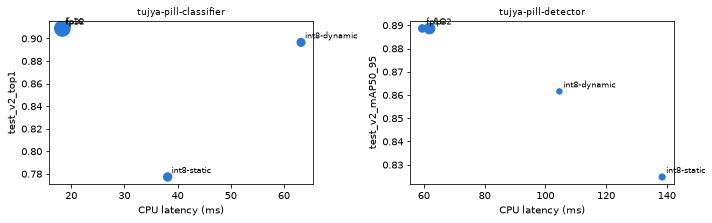

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, (model, group) in zip(axes, variants.groupby("model"), strict=True):
    ax.scatter(group.latency_ms, group.accuracy, s=group.size_mb * 3, color="#2a78d6")
    for _, r in group.iterrows():
        ax.annotate(
            r.variant,
            (r.latency_ms, r.accuracy),
            fontsize=8,
            xytext=(4, 4),
            textcoords="offset points",
        )
    ax.set_xlabel("CPU latency (ms)")
    ax.set_ylabel(group.metric.iloc[0])
    ax.set_title(model, fontsize=9)
plt.tight_layout()
plt.show()

## 2. The rule that picks the served variant

`src/models/quantize.py` `choose_variant`: the fastest variant that loses at most `max_drop`
of accuracy **and** is at least `min_speedup` faster than FP32; otherwise FP32 stays.
Thresholds from `params.yaml` `optimize`.

In [4]:
import yaml

from src.models.quantize import VariantResult, choose_variant

settings = yaml.safe_load((ROOT / "params.yaml").read_text(encoding="utf-8"))["optimize"]
print({k: settings[k] for k in ("max_drop", "min_speedup")})
for model, group in variants.groupby("model"):
    choice = choose_variant(
        [
            VariantResult(r.variant, r.accuracy, r.latency_ms, r.latency_p95_ms, r.size_mb)
            for r in group.itertuples()
        ],
        max_drop=settings["max_drop"],
        min_speedup=settings["min_speedup"],
    )
    print(f"{model}: served variant = {choice.precision}")

{'max_drop': 0.01, 'min_speedup': 0.05}
tujya-pill-classifier: served variant = fp32
tujya-pill-detector: served variant = fp32


**Takeaway:** FP16 keeps the accuracy but is less than 5 % faster, INT8 loses accuracy and is
slower on this CPU: both champions are served in FP32.